In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

chicks = pd.read_csv("chickwts.csv")

print(chicks.shape)
print(chicks.columns.tolist())
chicks.head()

(71, 3)
['Unnamed: 0', 'weight', 'feed']


,Unnamed: 0,weight,feed
0,1,179,horsebean
1,2,160,horsebean
2,3,136,horsebean
3,4,227,horsebean
4,5,217,horsebean


In [2]:
feed_means = chicks.groupby("feed")["weight"].mean().sort_values()

print(feed_means)

feed
horsebean    160.200000
linseed      218.750000
soybean      246.428571
meatmeal     276.909091
casein       323.583333
sunflower    328.916667
Name: weight, dtype: float64


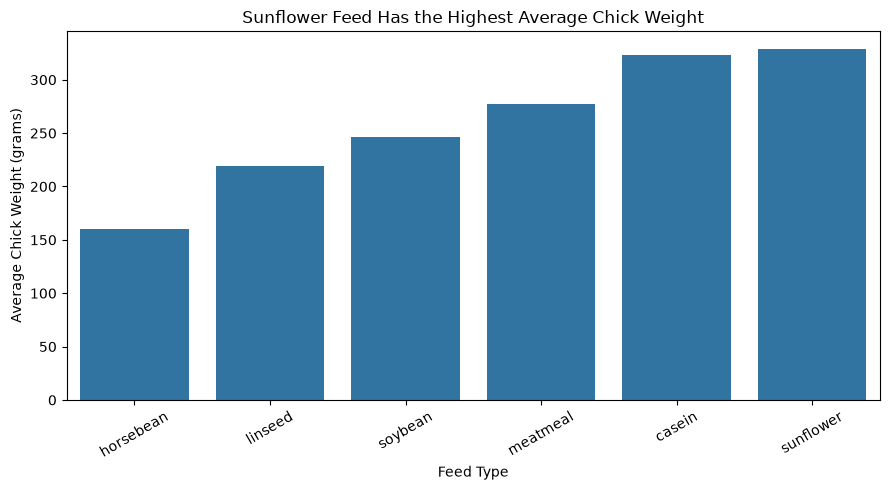

In [3]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=chicks,
    x="feed",
    y="weight",
    order=feed_means.index,
    errorbar=None
)

plt.title("Sunflower Feed Has the Highest Average Chick Weight")
plt.xlabel("Feed Type")
plt.ylabel("Average Chick Weight (grams)")
plt.ylim(bottom=0)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

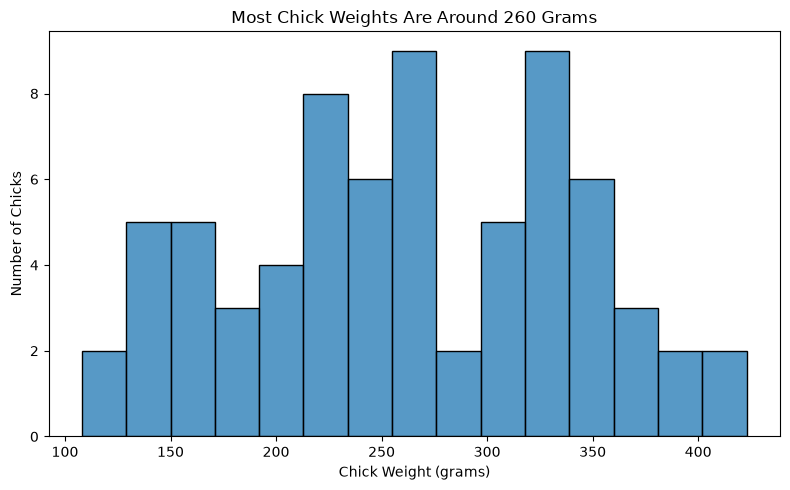

In [4]:
plt.figure(figsize=(8, 5))

sns.histplot(data=chicks, x="weight", bins=15)

plt.title("Most Chick Weights Are Around 260 Grams")
plt.xlabel("Chick Weight (grams)")
plt.ylabel("Number of Chicks")
plt.tight_layout()
plt.show()

In [5]:
museum = pd.read_csv("museum_visitors.csv")

print(museum.shape)
print(museum.columns.tolist())
museum.head()

(59, 5)
['Date', 'Avila Adobe', 'Firehouse Museum', 'Chinese American Museum', 'America Tropical Interpretive Center']


,Date,Avila Adobe,Firehouse Museum,Chinese American Museum,America Tropical Interpretive Center
0,2014-01-01,24778,4486,1581,6602
1,2014-02-01,18976,4172,1785,5029
2,2014-03-01,25231,7082,3229,8129
3,2014-04-01,26989,6756,2129,2824
4,2014-05-01,36883,10858,3676,10694


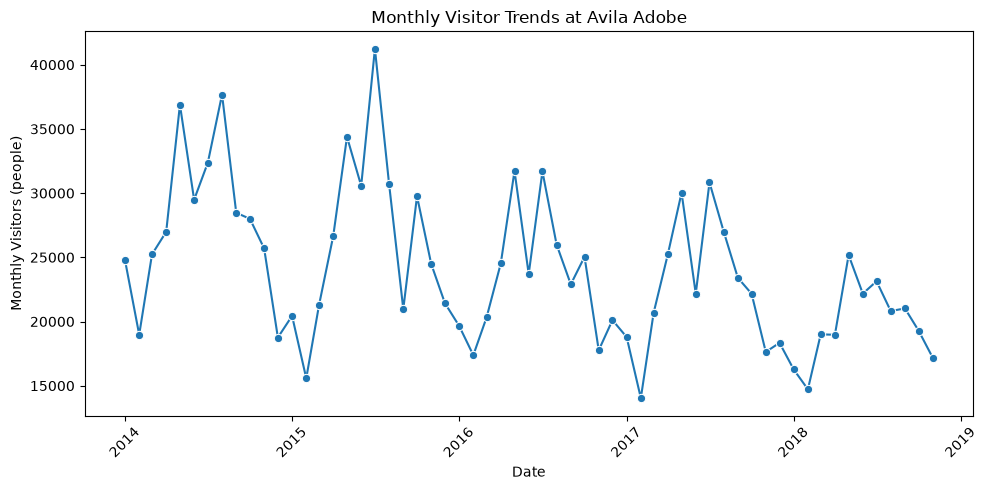

In [6]:
museum["Date"] = pd.to_datetime(museum["Date"])

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=museum,
    x="Date",
    y="Avila Adobe",
    marker="o"
)

plt.title("Monthly Visitor Trends at Avila Adobe")
plt.xlabel("Date")
plt.ylabel("Monthly Visitors (people)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The total amount of montly visitors at Avila Adobe was up and down between 2014 and 2018. Overall tho, the museum seems to have had fewer visitors toward the end compared to some of its earlier years.

In [7]:
sales = pd.read_csv("sales_clean.csv")
sales["revenue"] = sales["price"] * sales["qty"]

print(sales.shape)
sales.head()

(292, 7)


,order_id,date,product,price,qty,zip,revenue
0,1254,2026-04-06,mug,11.36,4,60614,45.44
1,1057,2026-05-30,charger,14.79,3,30303,44.37
2,1150,2026-05-06,mug,5.50,1,10001,5.50
3,1066,2026-05-30,notebook,37.53,1,98101,37.53
4,1114,2026-04-06,webcam,45.59,4,90405,182.36


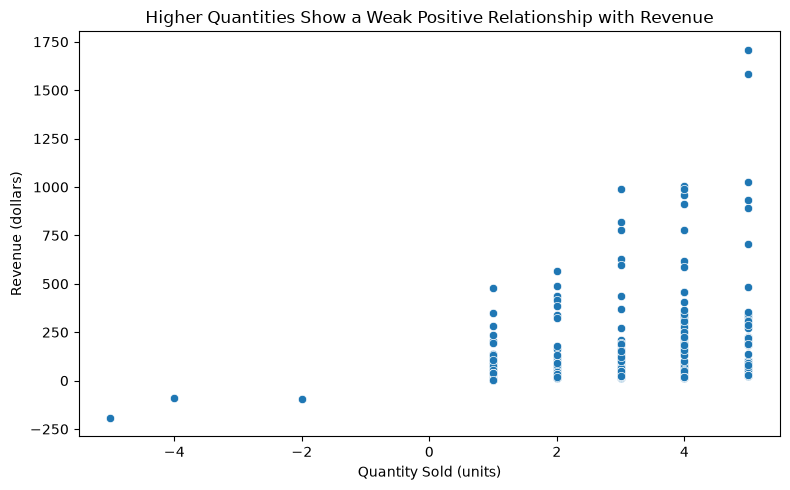

In [8]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=sales, x="qty", y="revenue")

plt.title("Higher Quantities Show a Weak Positive Relationship with Revenue")
plt.xlabel("Quantity Sold (units)")
plt.ylabel("Revenue (dollars)")
plt.tight_layout()
plt.show()

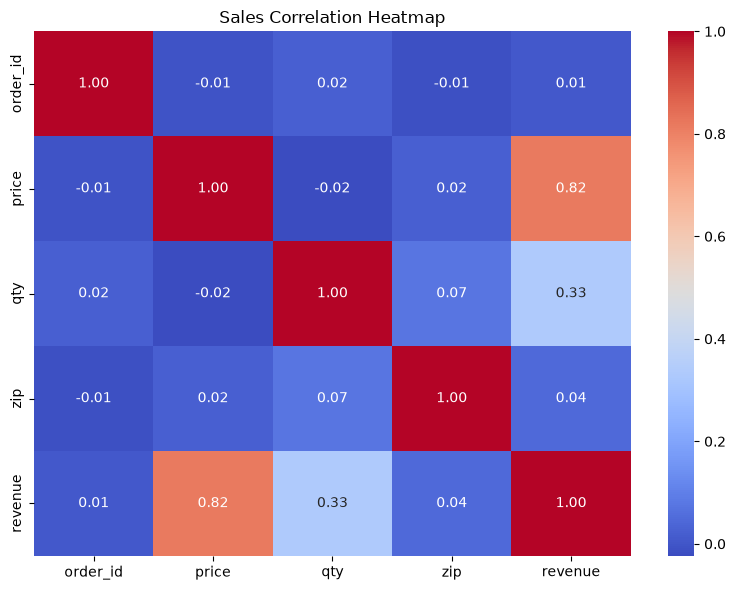

In [9]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    sales.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Sales Correlation Heatmap")
plt.tight_layout()
plt.show()

The strongest correlation is between price and revenue (r = 0.82). What this shows is that higher-priced items generally have higher revenue in this dataset.

My null hypothesis is that sunflower-fed chicks and horsebean-fed chicks are going to have the same average weight, which means that there isn't difference between the two groups.

In [10]:
sunflower = chicks[chicks["feed"] == "sunflower"]["weight"]
horsebean = chicks[chicks["feed"] == "horsebean"]["weight"]

t_stat, p_value = ttest_ind(sunflower, horsebean)

print("Sunflower mean:", sunflower.mean())
print("Horsebean mean:", horsebean.mean())
print("Difference in grams:", sunflower.mean() - horsebean.mean())
print("T-statistic:", t_stat)
print("P-value:", p_value)
print("Sample sizes:", len(sunflower), len(horsebean))

Sunflower mean: 328.9166666666667
Horsebean mean: 160.2
Difference in grams: 168.7166666666667
T-statistic: 8.848346742516636
P-value: 2.3743507676837164e-08
Sample sizes: 12 10


The results were that the sunflower-fed chicks weighed about a 168.72 grams more than the horsebean-fed chicks on average, and because the p-value was extremely low (0.0000000237), I would reject the null hypothesis. However, the small sample of 22 chicks means we should be careful about applying these results to other farms.

For my bar chart, I made sure the y-axis started at zero so that the differences between the feed types wouldn't be seen as exaggerated. I also labeled the weights in grams so people could clearly understand what the numbers represented.

GitHub Repository:
https://github.com/leonhong2007/cs82a-portfolio/tree/main/module5